# Riesgo de escalamiento a segundo nivel

**Pregunta.** Al abrir un ticket, ¿qué probabilidad hay de que termine escalado a nivel 2?
El objetivo es `escalado`. La salida se interpreta como una señal para priorizar la revisión,
ya que el histórico refleja derivaciones registradas, incluidas las que eran necesarias.

Comparamos los datos disponibles al abrir el ticket, el aporte estimado de una intención inferida
y una referencia con la intención registrada. Los tres escenarios se miden sobre las mismas filas
y ventanas cronológicas.

## Reproducción

Desde la raíz de `claro-copilot`, ejecute el notebook en CPU con el entorno fijado del servicio.

```bash
uv run --project services/ml --frozen --python 3.12 \
  --with ipykernel==6.29.5 --with nbclient==0.10.2 --with matplotlib==3.10.0 \
  --with onnxruntime==1.23.2 --with tokenizers==0.22.2 --with huggingface-hub==0.36.0 \
  --with xgboost==3.0.5 \
  jupyter-execute --inplace --timeout=600 services/ml/notebooks/comparacion_escalamiento.ipynb
```

Para abrirlo en Jupyter, use un kernel con las mismas dependencias. La carpeta de insumos se busca
al ascender desde el directorio de trabajo. También puede especificarla con `CLARO_INSUMOS_DIR`.
La ejecución conserva las fuentes en modo lectura y muestra únicamente resultados agregados.

In [1]:
import hashlib
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.calibration import CalibrationDisplay
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay, average_precision_score, brier_score_loss, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

seed = 42
cwd = Path.cwd()
ancestors = (cwd, *cwd.parents)
root = next((p for p in ancestors if (p / "services/ml/pyproject.toml").is_file()), None)
if root is None:
    raise FileNotFoundError("Ejecute el notebook desde el repositorio claro-copilot.")

override = os.getenv("CLARO_INSUMOS_DIR")
insumos = Path(override).expanduser() if override else next(
    (p / "Insumos_Prueba_Consultor_IA" for p in ancestors
     if (p / "Insumos_Prueba_Consultor_IA").is_dir()),
    root.parent / "Insumos_Prueba_Consultor_IA",
)
if not (insumos / "03_datos").is_dir():
    raise FileNotFoundError("Configure CLARO_INSUMOS_DIR con la ruta a los insumos.")

pd.options.display.max_columns = 18
plt.rcParams.update({"figure.dpi": 125, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {sys.version.split()[0]} · scikit-learn {sklearn.__version__} · pandas {pd.__version__}")

def read_csv(name):
    path = insumos / "03_datos" / name
    print(f"{name} · SHA-256 {hashlib.sha256(path.read_bytes()).hexdigest()}")
    return pd.read_csv(path)

Python 3.12.14 · scikit-learn 1.6.1 · pandas 2.2.3


## Datos y momento de predicción

El historial de apertura incluye canal, servicio, hora, día de la semana y actividad anterior
del cliente. Los tickets anteriores entran a los conteos por fecha de apertura. Un escalamiento
anterior solo cuenta si su ticket ya había cerrado. El cierre se estima sumando la duración a la
fecha de apertura porque el dataset carece de fechas precisas de escalamiento y cierre.

La cohorte supervisada conserva tickets con estado final observable al corte del histórico
(inicio del 1 de noviembre de 2026). Se excluyen duraciones negativas y el valor de 9.999 horas,
y se cuenta por separado lo que cruza el corte. Los conteos de aperturas previas incluyen esos
tickets cuando su fecha de creación es válida. Los identificadores, satisfacción, duración y
fecha de cierre quedan fuera de los predictores. El identificador de cliente sirve para armar
su historial.

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay, f1_score
from sklearn.svm import LinearSVC

sys.path.insert(0, str(root / "services/ml"))
from app.common import LABELS, group, normalize

raw_tickets = read_csv("tickets.csv")
tickets = raw_tickets.drop_duplicates().reset_index(drop=True)
required = {
    "ticket_id", "cliente_id", "fecha_creacion", "canal", "servicio",
    "categoria", "descripcion", "escalado", "tiempo_resolucion_horas",
}
assert required <= set(tickets) and tickets["ticket_id"].is_unique
assert tickets[["ticket_id", "cliente_id", "fecha_creacion", "escalado"]].notna().all().all()
assert set(tickets["escalado"]) == {0, 1}
tickets["categoria"] = tickets["categoria"].str.strip().str.lower()
assert set(tickets["categoria"]) == LABELS

tickets["fecha_creacion"] = pd.to_datetime(tickets["fecha_creacion"], errors="raise")
cutoff = pd.Timestamp("2026-11-01")
duration = pd.to_numeric(tickets["tiempo_resolucion_horas"], errors="coerce")
valid_duration = duration.ge(0) & duration.lt(9999)
tickets["cierre_estimado"] = tickets["fecha_creacion"] + pd.to_timedelta(duration.where(valid_duration), unit="h")
mature = valid_duration & tickets["cierre_estimado"].lt(cutoff) & tickets["fecha_creacion"].lt(cutoff)

audit = pd.Series({
    "Filas recibidas": len(raw_tickets),
    "Duplicados exactos": len(raw_tickets) - len(tickets),
    "Tickets únicos": len(tickets),
    "Escalamientos en tickets únicos": int(tickets["escalado"].sum()),
    "Duraciones negativas": int(duration.lt(0).sum()),
    "Duraciones de 9.999 horas": int(duration.eq(9999).sum()),
    "Otras duraciones inválidas": int((~valid_duration & ~duration.lt(0) & ~duration.eq(9999)).sum()),
    "Cierres estimados fuera del corte": int((valid_duration & ~mature).sum()),
    "Tickets elegibles para supervisión": int(mature.sum()),
    "Escalamientos elegibles para supervisión": int(tickets.loc[mature, "escalado"].sum()),
}, name="Resultado")
display(audit.to_frame())

def prior_counts(events, as_of, days):
    # Ambos extremos se buscan antes del evento actual. El extremo inferior es inclusivo.
    upper = np.searchsorted(events, as_of, side="left")
    lower = np.searchsorted(events, as_of - np.timedelta64(days, "D"), side="left")
    return upper - lower

# Verificar el borde de 30 días y la exclusión de un evento simultáneo.
example = np.array(["2026-06-01", "2026-06-02", "2026-07-02"], dtype="datetime64[D]")
assert prior_counts(example, example[-1:], 30).tolist() == [1]

history_fields = ["tickets_previos_30d", "tickets_previos_90d", "escalados_cerrados_90d"]
tickets[history_fields] = 0
for _, client in tickets.groupby("cliente_id", sort=False):
    opened = client["fecha_creacion"].to_numpy(dtype="datetime64[ns]")
    closed_escalations = client.loc[
        client["escalado"].eq(1) & client["cierre_estimado"].notna(), "cierre_estimado"
    ].to_numpy(dtype="datetime64[ns]")
    tickets.loc[client.index, history_fields] = np.column_stack([
        prior_counts(np.sort(opened), opened, 30),
        prior_counts(np.sort(opened), opened, 90),
        prior_counts(np.sort(closed_escalations), opened, 90),
    ])
assert tickets[history_fields].ge(0).all().all()
assert tickets["tickets_previos_30d"].le(tickets["tickets_previos_90d"]).all()
eligible = tickets.loc[mature].reset_index(drop=True)
assert eligible["cierre_estimado"].ge(eligible["fecha_creacion"]).all()

tickets.csv · SHA-256 c922f1984c060433d74daf561289e88a1d82151c403461614ec5e991a2a27d96


,Resultado
Filas recibidas,3816
Duplicados exactos,20
Tickets únicos,3796
Escalamientos en tickets únicos,818
Duraciones negativas,11
Duraciones de 9.999 horas,11
Otras duraciones inválidas,0
Cierres estimados fuera del corte,4
Tickets elegibles para supervisión,3770
Escalamientos elegibles para supervisión,813


## Intención inferida como aproximación al primer turno

Reutilizamos el codificador congelado `multilingual-e5-small` del notebook de intención. El SVM
lineal se entrena desde enero, al comienzo de cada mes, con notas y categorías de tickets cerrados
antes de ese mes. Así cada predicción auxiliar se construye con información anterior al ticket.
El codificador es independiente de las etiquetas y vectoriza cada texto en memoria.

El CSV contiene notas de asesores. Una nota puede aportar detalles que todavía no existían al
abrir el caso. La medición de este escenario estima el aporte de una intención inferida **sobre
esas notas**. El corpus de primeros turnos carece de una clave compartida con el CSV, por lo que
ese aporte necesita validación con primeros turnos y desenlaces enlazados.

[Modelo y configuración de E5](https://huggingface.co/intfloat/multilingual-e5-small) ·
[SVM lineal](https://scikit-learn.org/1.6/modules/generated/sklearn.svm.LinearSVC.html)

In [3]:
import warnings

# En ejecución sin widgets, tqdm usa la salida de texto.
warnings.filterwarnings("ignore", message=r"IProgress not found\.", module=r"tqdm\.auto")

import onnxruntime as ort
from huggingface_hub import hf_hub_download
from tokenizers import Tokenizer

e5_repo = "intfloat/multilingual-e5-small"
e5_revision = "614241f622f53c4eeff9890bdc4f31cfecc418b3"
tokenizer_path = hf_hub_download(e5_repo, "onnx/tokenizer.json", revision=e5_revision, token=False)
encoder_path = hf_hub_download(e5_repo, "onnx/model.onnx", revision=e5_revision, token=False)
tokenizer = Tokenizer.from_file(tokenizer_path)
tokenizer.enable_truncation(max_length=512)
tokenizer.enable_padding(pad_id=tokenizer.token_to_id("<pad>"), pad_token="<pad>")
session_options = ort.SessionOptions()
session_options.intra_op_num_threads = 2
encoder = ort.InferenceSession(encoder_path, session_options, providers=["CPUExecutionProvider"])

def encode_texts(texts, batch_size=16):
    unique = list(dict.fromkeys(texts))
    inputs = {item.name for item in encoder.get_inputs()}
    encoded = []
    for start in range(0, len(unique), batch_size):
        batch = tokenizer.encode_batch([f"query: {text}" for text in unique[start:start + batch_size]])
        tensors = {
            "input_ids": np.array([item.ids for item in batch], dtype=np.int64),
            "attention_mask": np.array([item.attention_mask for item in batch], dtype=np.int64),
            "token_type_ids": np.array([item.type_ids for item in batch], dtype=np.int64),
        }
        hidden, = encoder.run(["last_hidden_state"], {key: tensors[key] for key in inputs})
        mask = tensors["attention_mask"][..., np.newaxis]
        pooled = (hidden * mask).sum(axis=1, dtype=np.float32) / mask.sum(axis=1, dtype=np.float32)
        encoded.extend(pooled / np.linalg.norm(pooled, axis=1, keepdims=True))
    vectors = dict(zip(unique, encoded))
    return pd.DataFrame(np.stack([vectors[text] for text in texts]), index=texts.index)

In [4]:
dates = eligible["fecha_creacion"]
notes = eligible["descripcion"].fillna("").map(normalize)
assert notes.ne("").all()
embeddings = encode_texts(notes)
note_groups = notes.map(group)
proxy = pd.Series(index=eligible.index, dtype="object")
proxy_audit = []
for month in pd.date_range("2026-01-01", cutoff, freq="MS", inclusive="left"):
    train_mask = dates.lt(month) & eligible["cierre_estimado"].lt(month)
    test_mask = dates.ge(month) & dates.lt(month + pd.offsets.MonthBegin(1))
    assert not (train_mask & test_mask).any() and set(eligible.loc[train_mask, "categoria"]) == LABELS
    assert proxy.loc[test_mask].isna().all()
    clf = LinearSVC(C=1.0, class_weight="balanced", random_state=seed)
    clf.fit(embeddings.loc[train_mask], eligible.loc[train_mask, "categoria"])
    proxy.loc[test_mask] = clf.predict(embeddings.loc[test_mask])
    proxy_audit.append({
        "Mes": month.strftime("%Y-%m"), "Tickets previos para ajuste": int(train_mask.sum()),
        "Tickets predichos": int(test_mask.sum()),
        "F1 macro de intención": f1_score(eligible.loc[test_mask, "categoria"], proxy.loc[test_mask],
                                         labels=sorted(LABELS), average="macro", zero_division=0),
        "Proporción con plantilla conocida": note_groups.loc[test_mask].isin(note_groups.loc[train_mask]).mean(),
    })
assert proxy.notna().equals(dates.ge(pd.Timestamp("2026-01-01")))
display(pd.DataFrame(proxy_audit).set_index("Mes").round(3))

# Los tres escenarios tienen cobertura común a partir de enero.
data = eligible.loc[proxy.notna()].assign(intencion_inferida=proxy.dropna()).reset_index(drop=True)
data["bloque_horario"] = (data["fecha_creacion"].dt.hour // 4).astype(str)
data["dia_semana"] = data["fecha_creacion"].dt.dayofweek.astype(str)
opening_cat = ["canal", "servicio", "bloque_horario", "dia_semana"]
opening = data[opening_cat + history_fields].copy()
opening[opening_cat] = opening[opening_cat].fillna("__sin_dato__").astype(str)
feature_sets = {
    "Apertura": opening,
    "Apertura + intención inferida": opening.assign(intencion_inferida=data["intencion_inferida"]),
    "Apertura + intención registrada": opening.assign(intencion_registrada=data["categoria"]),
}
for scenario, X in feature_sets.items():
    assert X.index.equals(data.index)
    assert not {"ticket_id", "cliente_id", "satisfaccion", "tiempo_resolucion_horas",
                "cierre_estimado", "escalado", "descripcion", "categoria"} & set(X)
    if scenario == "Apertura":
        assert set(X) == set(opening_cat + history_fields)
y = data["escalado"].astype(int)

,Tickets previos para ajuste,Tickets predichos,F1 macro de intención,Proporción con plantilla conocida
Mes,,,,
2026-01,612,303,0.974,1.0
2026-02,913,292,0.966,1.0
2026-03,1211,297,0.947,1.0
2026-04,1507,316,0.974,1.0
2026-05,1821,348,0.972,1.0
2026-06,2171,306,0.993,1.0
2026-07,2476,346,0.964,1.0
2026-08,2819,335,0.959,1.0
2026-09,3159,306,0.982,1.0


## Ajuste y ventanas de evaluación

Comparamos prevalencia, regresión logística L2, Random Forest e HistGradientBoosting.
Los modelos lineales permiten medir el aporte de señales simples y los árboles prueban
interacciones. Las categorías, imputaciones y escalas se ajustan dentro de cada ventana.

Se desarrolla con **mayo–junio** y **julio–agosto**, usando en cada ajuste solo tickets con cierre
estimado anterior al inicio de la ventana. Se seleccionan hiperparámetros por AP promedio,
luego ROC-AUC y Brier. Los mejores parámetros de cada combinación se fijan antes de puntuar
**septiembre–octubre**.

[Validación temporal](https://scikit-learn.org/1.6/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) ·
[Random Forest](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.RandomForestClassifier.html) ·
[HistGradientBoosting](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)

El clasificador auxiliar conserva el ciclo mensual en la prueba. Para octubre puede usar
intenciones de septiembre cuyo ticket ya había cerrado. El modelo de riesgo de escalamiento
se ajusta una sola vez al inicio de septiembre y se mantiene fijo en los dos meses.

In [5]:
def tabular_models(cat, num):
    def encoder(dense=False, scale=False):
        numeric = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
        if scale:
            numeric = make_pipeline(numeric, StandardScaler())
        return ColumnTransformer([
            ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=not dense), cat),
            ("numericas", numeric, num),
        ], sparse_threshold=0 if dense else 0.3)

    return {
        "Prevalencia": (DummyClassifier(strategy="prior"), {}),
        "Regresión logística L2": (
            make_pipeline(encoder(scale=True), LogisticRegression(solver="liblinear", max_iter=1000,
                                                                 random_state=seed)),
            {"logisticregression__C": [0.1, 1.0, 10.0]},
        ),
        "Random Forest": (
            make_pipeline(encoder(), RandomForestClassifier(n_estimators=240, n_jobs=2, random_state=seed)),
            {"randomforestclassifier__max_depth": [4, 8],
             "randomforestclassifier__min_samples_leaf": [8, 20]},
        ),
        "HistGradientBoosting": (
            make_pipeline(encoder(dense=True), HistGradientBoostingClassifier(
                max_iter=150, learning_rate=0.05, early_stopping=False, random_state=seed
            )),
            {"histgradientboostingclassifier__max_leaf_nodes": [7, 15],
             "histgradientboostingclassifier__min_samples_leaf": [20, 40]},
        ),
    }

def metrics(actual, score):
    return {
        "ROC-AUC": roc_auc_score(actual, score),
        "AP": average_precision_score(actual, score),
        "Brier": brier_score_loss(actual, score),
    }

def fits_and_scores(model, params, X, y, train, test):
    fitted = clone(model).set_params(**params).fit(X.iloc[train], y.iloc[train])
    return fitted.predict_proba(X.iloc[test])[:, 1]

def choose_models(feature_sets, model_sets, y, splits, ranking):
    rows = []
    for scenario, X in feature_sets.items():
        for name, (model, grid) in model_sets[scenario].items():
            for params in ParameterGrid(grid):
                oof = np.full(len(y), np.nan)
                results = []
                for train, validation in splits:
                    scores = fits_and_scores(model, params, X, y, train, validation)
                    assert np.isnan(oof[validation]).all()
                    oof[validation] = scores
                    results.append(metrics(y.iloc[validation], scores))
                fold_scores = pd.DataFrame(results)
                rows.append({
                    "Escenario": scenario, "Modelo": name, "Parámetros": params,
                    **fold_scores.mean().to_dict(), **(fold_scores.std(ddof=0).add_suffix(" DE").to_dict()),
                    "folds": results, "oof": oof,
                })
    trials = pd.DataFrame(rows).sort_values(ranking, ascending=[False, False, True], kind="stable")
    return trials.drop_duplicates(["Escenario", "Modelo"]).reset_index(drop=True)

def test_models(picks, feature_sets, model_sets, y, train, test):
    scores = {}
    for _, row in picks.iterrows():
        scenario, name = row["Escenario"], row["Modelo"]
        model, _ = model_sets[scenario][name]
        scores[scenario, name] = fits_and_scores(
            model, row["Parámetros"], feature_sets[scenario], y, train, test,
        )
    return scores

def at_capacity(actual, scores, fraction):
    y = np.asarray(actual, dtype=int)
    # La misma semilla rompe empates para todas las curvas y modelos.
    tie_break = np.random.default_rng(seed).permutation(len(y))
    order = np.lexsort((tie_break, -np.asarray(scores)))
    k = int(np.ceil(fraction * len(y)))
    tp = int(y[order[:k]].sum())
    precision = tp / k
    return {
        "Revisados": k, "Positivos capturados": tp, "Falsos positivos": k - tp,
        "Precisión": precision, "Recall": tp / y.sum(), "Lift": precision / y.mean(),
    }

def comparison_plots(actual, scores, title):
    fig, (ax_pr, ax_cal) = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained")
    for label, values in scores.items():
        if np.ptp(values) > 0:
            PrecisionRecallDisplay.from_predictions(actual, values, name=label, ax=ax_pr)
        CalibrationDisplay.from_predictions(actual, values, n_bins=5, strategy="quantile",
                                            name=label, ax=ax_cal)
    ax_pr.axhline(np.mean(actual), linewidth=1, linestyle="--", color="#666666", label="Tasa base")
    ax_pr.legend(loc="upper right", fontsize=8)
    handles, labels = ax_cal.get_legend_handles_labels()
    labels = ["Calibración ideal" if value == "Perfectly calibrated" else value for value in labels]
    ax_cal.legend(handles, labels, loc="lower right", fontsize=8)
    ax_pr.set(title="Precisión y recall", xlabel="Recall", ylabel="Precisión")
    ax_cal.set(title="Calibración", xlabel="Probabilidad media predicha",
               ylabel="Proporción de casos positivos")
    fig.suptitle(title, x=0.02, ha="left")
    plt.show()

def decimal(value):
    return f"{value:.3f}".replace(".", ",")

In [6]:
def window(start, end):
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    train = np.flatnonzero(data["fecha_creacion"].lt(start) & data["cierre_estimado"].lt(start))
    test = np.flatnonzero(data["fecha_creacion"].ge(start) & data["fecha_creacion"].lt(end))
    assert not set(train) & set(test)
    assert data["cierre_estimado"].iloc[train].max() < start
    assert data["fecha_creacion"].iloc[test].between(start, end, inclusive="left").all()
    assert set(y.iloc[train]) == set(y.iloc[test]) == {0, 1}
    return train, test

windows = [("2026-05-01", "2026-07-01"), ("2026-07-01", "2026-09-01"),
           ("2026-09-01", "2026-11-01")]
early, late, final = [window(start, end) for start, end in windows]
dev_splits = [early, late]
dev, test = final
assert not set(test) & set(np.concatenate([idx for split in dev_splits for idx in split]))
display(pd.DataFrame([
    {
        "Inicio": start, "Fin exclusivo": end, "Entrenamiento": len(tr),
        "Evaluación": len(te), "Escalados en evaluación": int(y.iloc[te].sum()),
        "Clientes compartidos": len(
            set(data["cliente_id"].iloc[tr]) & set(data["cliente_id"].iloc[te])
        ),
    }
    for (start, end), (tr, te) in zip(windows, [early, late, final])
]).set_index("Inicio"))

model_sets = {
    scenario: tabular_models([column for column in X if column not in history_fields], history_fields)
    for scenario, X in feature_sets.items()
}
ranking = ["AP", "ROC-AUC", "Brier"]
with threadpool_limits(limits=2):
    picks = choose_models(feature_sets, model_sets, y, dev_splits, ranking)
    champions = picks.loc[picks["Modelo"].ne("Prevalencia")].drop_duplicates("Escenario").set_index("Escenario")
    thresholds = {
        scenario: float(np.quantile(row["oof"][np.isfinite(row["oof"])], 0.8, method="higher"))
        for scenario, row in champions.iterrows()
    }
    heldout = test_models(picks, feature_sets, model_sets, y, dev, test)

dev_table = picks[["Escenario", "Modelo", *ranking, "AP DE", "Parámetros"]].copy()
dev_table["AP mayo–junio"] = picks["folds"].map(lambda results: results[0]["AP"])
dev_table["AP julio–agosto"] = picks["folds"].map(lambda results: results[1]["AP"])
display(dev_table.round(3))

,Fin exclusivo,Entrenamiento,Evaluación,Escalados en evaluación,Clientes compartidos
Inicio,,,,,
2026-05-01,2026-07-01,1204,654,141,249
2026-07-01,2026-09-01,1859,681,153,312
2026-09-01,2026-11-01,2542,610,127,340


,Escenario,Modelo,AP,ROC-AUC,Brier,AP DE,Parámetros,AP mayo–junio,AP julio–agosto
0,Apertura + intención registrada,Regresión logística L2,0.327,0.668,0.160,0.001,{'logisticregression__C': 1.0},0.328,0.325
1,Apertura + intención registrada,Random Forest,0.325,0.659,0.160,0.024,"{'randomforestclassifier__max_depth': 8, 'rand...",0.301,0.348
2,Apertura + intención inferida,Regresión logística L2,0.321,0.664,0.160,0.001,{'logisticregression__C': 10.0},0.319,0.322
3,Apertura + intención inferida,Random Forest,0.317,0.654,0.161,0.025,"{'randomforestclassifier__max_depth': 8, 'rand...",0.293,0.342
4,Apertura + intención registrada,HistGradientBoosting,0.315,0.649,0.170,0.032,{'histgradientboostingclassifier__max_leaf_nod...,0.283,0.347
5,Apertura + intención inferida,HistGradientBoosting,0.312,0.645,0.170,0.035,{'histgradientboostingclassifier__max_leaf_nod...,0.277,0.347
6,Apertura,Prevalencia,0.220,0.500,0.172,0.005,{},0.216,0.225
7,Apertura + intención inferida,Prevalencia,0.220,0.500,0.172,0.005,{},0.216,0.225
8,Apertura + intención registrada,Prevalencia,0.220,0.500,0.172,0.005,{},0.216,0.225
9,Apertura,Random Forest,0.217,0.477,0.174,0.014,"{'randomforestclassifier__max_depth': 8, 'rand...",0.202,0.231


## Prueba reservada y capacidad de revisión

AP resume la curva de precisión y recall y es la métrica principal para detectar escalados con
una clase positiva minoritaria. La capacidad común del **20 %** permite comparar falsos positivos,
precisión, recall y lift con el mismo volumen. Los empates de score se resuelven con el mismo
orden aleatorio reproducible en todos los modelos. La prevalencia es la referencia esperada
para AP y precisión sin un ranking informativo.

Para la matriz de confusión y los cortes por canal y servicio se aplica el umbral congelado de
cada escenario, el percentil 80 de los scores de desarrollo. Con umbral fijo, el volumen observado
en la prueba puede diferir del 20 %. La tabla muestra esa diferencia.

[Average Precision](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.average_precision_score.html) ·
[Métricas probabilísticas y calibración](https://scikit-learn.org/1.6/modules/calibration.html)

ROC-AUC     AP  Brier
Escenario                       Modelo                                       
Apertura + intención registrada Regresión logística L2    0.702  0.375  0.150
                                Random Forest             0.685  0.392  0.151
Apertura + intención inferida   Regresión logística L2    0.722  0.385  0.147
                                Random Forest             0.705  0.410  0.149
Apertura + intención registrada HistGradientBoosting      0.675  0.348  0.155
Apertura + intención inferida   HistGradientBoosting      0.691  0.362  0.152
Apertura                        Prevalencia               0.500  0.208  0.165
Apertura + intención inferida   Prevalencia               0.500  0.208  0.165
Apertura + intención registrada Prevalencia               0.500  0.208  0.165
Apertura                        Random Forest             0.559  0.253  0.164
                                HistGradientBoosting      0.548  0.261  0.165
                                Regresión logística L2    0.591  0.261  0.163

Revisados  \
Escenario                       Modelo                              
Apertura + intención registrada Regresión logística L2        122   
                                Random Forest                 122   
Apertura + intención inferida   Regresión logística L2        122   
                                Random Forest                 122   
Apertura + intención registrada HistGradientBoosting          122   
Apertura + intención inferida   HistGradientBoosting          122   
Apertura                        Prevalencia                   122   
Apertura + intención inferida   Prevalencia                   122   
Apertura + intención registrada Prevalencia                   122   
Apertura                        Random Forest                 122   
                                HistGradientBoosting          122   
                                Regresión logística L2        122   

                                                        Positivos capturados  \
Escenario                       Modelo                                         
Apertura + intención registrada Regresión logística L2                    50   
                                Random Forest                             43   
Apertura + intención inferida   Regresión logística L2                    50   
                                Random Forest                             49   
Apertura + intención registrada HistGradientBoosting                      41   
Apertura + intención inferida   HistGradientBoosting                      42   
Apertura                        Prevalencia                               20   
Apertura + intención inferida   Prevalencia                               20   
Apertura + intención registrada Prevalencia                               20   
Apertura                        Random Forest                             27   
                                HistGradientBoosting                      29   
                                Regresión logística L2                    32   

                                                        Falsos positivos  \
Escenario                       Modelo                                     
Apertura + intención registrada Regresión logística L2                72   
                                Random Forest                         79   
Apertura + intención inferida   Regresión logística L2                72   
                                Random Forest                         73   
Apertura + intención registrada HistGradientBoosting                  81   
Apertura + intención inferida   HistGradientBoosting                  80   
Apertura                        Prevalencia                          102   
Apertura + intención inferida   Prevalencia                          102   
Apertura + intención registrada Prevalencia                          102   
Apertura                        Random Forest                         95   
                                HistGradientBoosting                  93   
                                Regresión logística L2                90   

                                                        Precisión  Recall  \
Escenario                       Modelo                                      
Apertura + intención registrada Regresión logística L2      0.410   0.394   
                                Random Forest               0.352   0.339   
Apertura + intención inferida   Regresión logística L2      0.410   0.394   
                                Random Forest               0.402   0.386   
Apertura + intención registrada HistGradientBoosting        0.336   0.323   
Apertura + intención inferida   HistGradientBoosting        0.344   0.331   
Apertura                        Prevalencia                 0.164   0.157   
Apertura + intención inferida   Prevalencia                 0.164   0.157   
Apertura + intención registrada Prevalencia                 0.164   0.157   
Apertura                        Random Forest           

,Modelo,Umbral de desarrollo,Tickets,Escalados,Alertas,Proporción de alertas,Falsos positivos,Precisión,Recall
Escenario,,,,,,,,,
Apertura,Random Forest,0.241,610,127,125,0.205,95,0.240,0.236
Apertura + intención inferida,Regresión logística L2,0.356,610,127,160,0.262,90,0.438,0.551
Apertura + intención registrada,Regresión logística L2,0.358,610,127,159,0.261,90,0.434,0.543


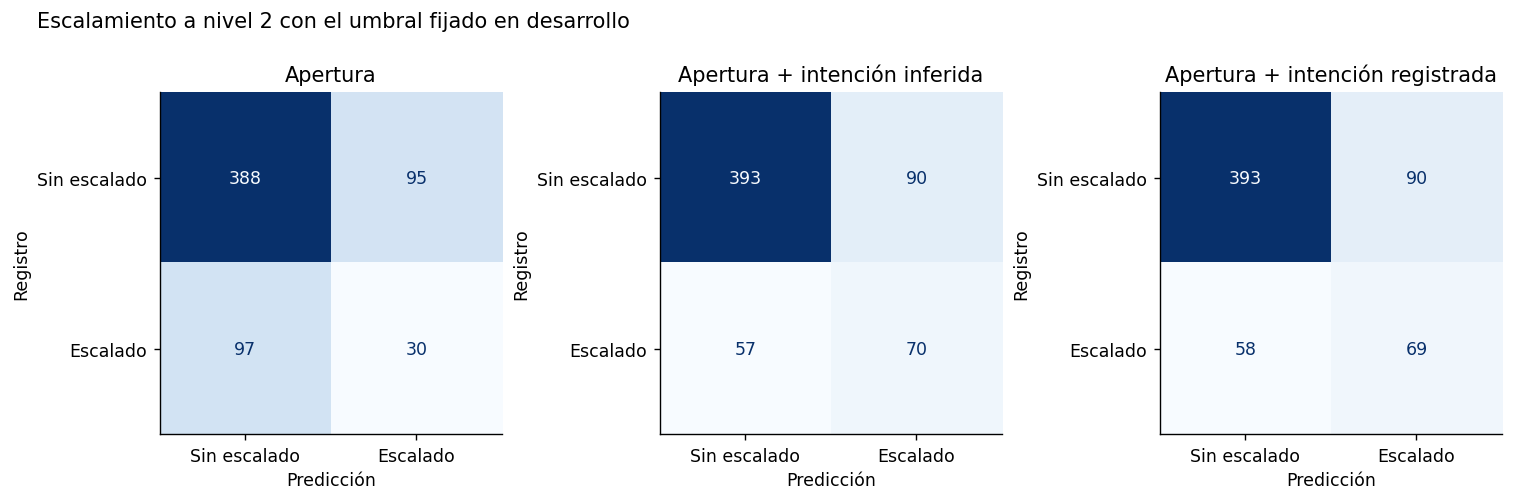

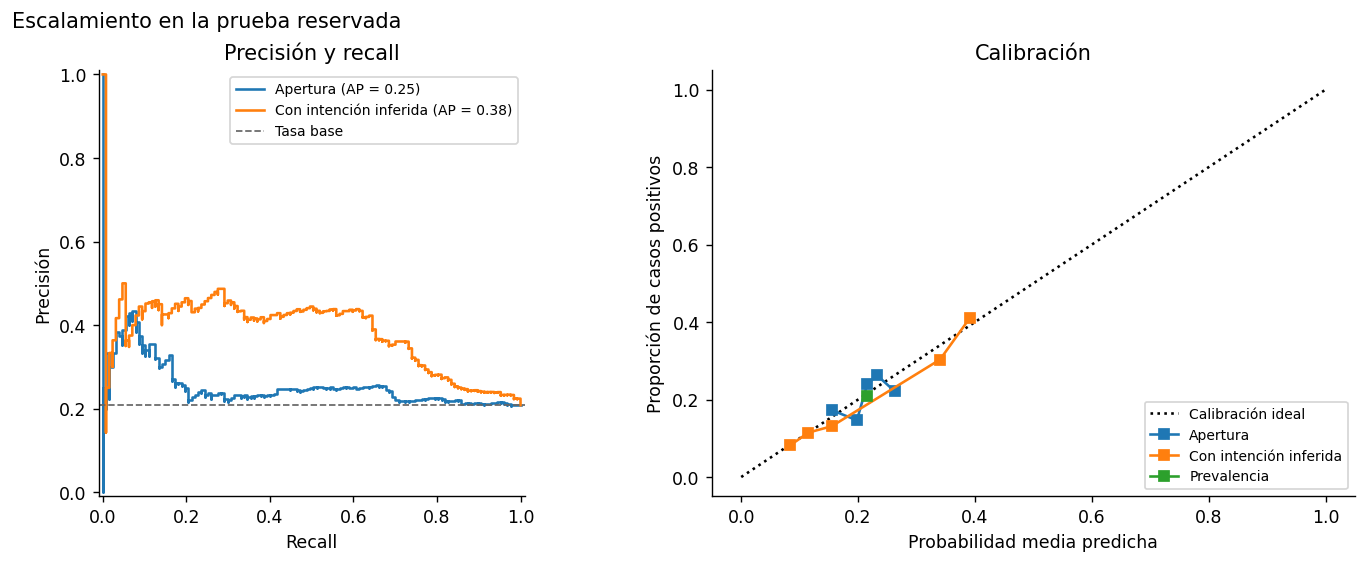

In [7]:
actual = y.iloc[test]
heldout_metrics = {key: metrics(actual, scores) for key, scores in heldout.items()}
test_table = pd.DataFrame.from_dict(heldout_metrics, orient="index")
test_table.index.names = ["Escenario", "Modelo"]
display(test_table.round(3))

capacity = pd.DataFrame([
    {"Escenario": key[0], "Modelo": key[1], **at_capacity(actual, scores, 0.20)}
    for key, scores in heldout.items()
])
display(capacity.set_index(["Escenario", "Modelo"]).round(3))

def alert_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=int)
    predicted = np.asarray(predicted, dtype=bool)
    true_positives = int(actual[predicted].sum())
    alerts = int(predicted.sum())
    positives = int(actual.sum())
    return {
        "Tickets": len(actual), "Escalados": positives, "Alertas": alerts,
        "Proporción de alertas": alerts / len(actual),
        "Falsos positivos": alerts - true_positives,
        "Precisión": true_positives / alerts if alerts else np.nan,
        "Recall": true_positives / positives if positives else np.nan,
    }

top_models = {scenario: (scenario, champions.loc[scenario, "Modelo"]) for scenario in feature_sets}
predicted = {scenario: heldout[key] >= thresholds[scenario] for scenario, key in top_models.items()}
threshold_report = [{
    "Escenario": scenario, "Modelo": key[1], "Umbral de desarrollo": thresholds[scenario],
    **alert_metrics(actual, predicted[scenario]),
} for scenario, key in top_models.items()]
display(pd.DataFrame(threshold_report).set_index("Escenario").round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for (scenario, pred), ax in zip(predicted.items(), axes):
    ConfusionMatrixDisplay.from_predictions(
        actual, pred.astype(int), labels=[0, 1], display_labels=["Sin escalado", "Escalado"],
        ax=ax, cmap="Blues", colorbar=False,
    )
    ax.set(title=scenario, xlabel="Predicción", ylabel="Registro")
fig.suptitle("Escalamiento a nivel 2 con el umbral fijado en desarrollo", x=0.02, ha="left")
plt.show()

comparison_plots(
    actual,
    {"Apertura": heldout[top_models["Apertura"]],
     "Con intención inferida": heldout[top_models["Apertura + intención inferida"]],
     "Prevalencia": heldout["Apertura", "Prevalencia"]},
    "Escalamiento en la prueba reservada",
)

In [8]:
segment_rows = []
test_data = data.iloc[test].reset_index(drop=True)
for scenario, key in top_models.items():
    for field in ("canal", "servicio"):
        for value, idx in test_data.groupby(field, dropna=False).indices.items():
            segment_y = actual.iloc[idx]
            segment_score = heldout[key][idx]
            segment_rows.append({
                "Escenario": scenario, "Variable": field, "Grupo": value,
                **alert_metrics(segment_y, predicted[scenario][idx]),
                "AP": average_precision_score(segment_y, segment_score)
                if segment_y.nunique() == 2 else np.nan,
            })
display(pd.DataFrame(segment_rows).set_index(["Escenario", "Variable", "Grupo"]).round(3))

opening_key = top_models["Apertura"]
proxy_key = top_models["Apertura + intención inferida"]
opening_ap = heldout_metrics[opening_key]["AP"]
proxy_ap = heldout_metrics[proxy_key]["AP"]
base_ap = heldout_metrics["Apertura", "Prevalencia"]["AP"]
same_model_proxy_ap = heldout_metrics["Apertura + intención inferida", opening_key[1]]["AP"]
proxy_cap = at_capacity(actual, heldout[proxy_key], 0.20)
selected = at_capacity(actual, heldout[opening_key], 0.20)
display(Markdown(
    f"**Apertura · {opening_key[1]}** obtuvo **AP {decimal(opening_ap)}** frente a "
    f"**{decimal(base_ap)}** del baseline. Al revisar {selected['Revisados']} tickets "
    f"capturó **{selected['Positivos capturados']}/{int(actual.sum())}** escalados con "
    f"**{selected['Falsos positivos']}** falsos positivos. La prueba con intención inferida sobre "
    f"las notas obtuvo **AP {decimal(proxy_ap)}** con **{proxy_key[1]}** y capturó "
    f"**{proxy_cap['Positivos capturados']}/{int(actual.sum())}** escalados con la misma capacidad. "
    f"Si mantenemos el tipo de modelo de apertura, añadir la intención inferida cambia "
    f"AP en **{decimal(same_model_proxy_ap - opening_ap)}**."
))

Tickets  Escalados  \
Escenario                       Variable Grupo                              
Apertura                        canal    app_mi_claro       63         17   
                                         call_center       258         48   
                                         chat              114         28   
                                         tienda             64         10   
                                         whatsapp          111         24   
                                servicio hogar             362         91   
                                         movil             248         36   
Apertura + intención inferida   canal    app_mi_claro       63         17   
                                         call_center       258         48   
                                         chat              114         28   
                                         tienda             64         10   
                                         whatsapp          111         24   
                                servicio hogar             362         91   
                                         movil             248         36   
Apertura + intención registrada canal    app_mi_claro       63         17   
                                         call_center       258         48   
                                         chat              114         28   
                                         tienda             64         10   
                                         whatsapp          111         24   
                                servicio hogar             362         91   
                                         movil             248         36   

                                                       Alertas  \
Escenario                       Variable Grupo                   
Apertura                        canal    app_mi_claro       10   
                                         call_center        54   
                                         chat               14   
                                         tienda              8   
                                         whatsapp           39   
                                servicio hogar              86   
                                         movil              39   
Apertura + intención inferida   canal    app_mi_claro       19   
                                         call_center        69   
                                         chat               27   
                                         tienda             11   
                                         whatsapp           34   
                                servicio hogar             107   
                                         movil              53   
Apertura + intención registrada canal    app_mi_claro       19   
                                         call_center        68   
                                         chat               26   
                                         tienda             11   
                                         whatsapp           35   
                                servicio hogar             109   
                                         movil              50   

                                                       Proporción de alertas  \
Escenario                       Variable Grupo                                 
Apertura                        canal    app_mi_claro                  0.159   
                                         call_center                   0.209   
                                         chat                          0.123   
                                         tienda                        0.125   
                                         whatsapp                      0.351   
                                servicio hogar                         0.238   
                                         movil                         0.157   
Apertura + intención inferida   canal    app

**Apertura · Random Forest** obtuvo **AP 0,253** frente a **0,208** del baseline. Al revisar 122 tickets capturó **27/127** escalados con **95** falsos positivos. La prueba con intención inferida sobre las notas obtuvo **AP 0,385** con **Regresión logística L2** y capturó **50/127** escalados con la misma capacidad. Si mantenemos el tipo de modelo de apertura, añadir la intención inferida cambia AP en **0,156**.

## Recomendación

Usar la comparación con datos de apertura para valorar el ranking en la demo. Para estimar el
beneficio de añadir intención en el primer turno, recolectar la salida del clasificador antes
de la resolución y enlazarla con un ticket de escalamiento. La decisión operativa también
requiere revisar si el modelo detecta escalados necesarios y cuántas alertas puede atender el
equipo. Un cambio en la tasa de escalamiento requiere una evaluación de la intervención.

## Segunda ronda · optimización de escalamiento

Un estudio de IBM comparó Random Forest y XGBoost y encontró valor al incorporar historial del
cliente y señales operativas con fecha. Adaptamos las señales que existen en Claro, preservando
el momento de predicción. El despliegue de enrutamiento de IBM también usó el texto de apertura
para inferir el área de soporte. Aquí comparamos convertir la nota en una categoría con conservar
más información, mediante probabilidades por intención, TF-IDF y embeddings E5 directos.

Conservamos las dos ventanas de desarrollo, el corte de etiquetas y la prueba de septiembre–octubre.
La selección se hace por AP de desarrollo. Como ya se consultó la prueba en la primera ronda,
los resultados nuevos sobre ella son retrospectivos. Se añade un control donde el modelo no ha
visto ninguna nota de la misma plantilla del ticket que pronostica.

[Investigación de IBM sobre escalamiento](https://arxiv.org/abs/2010.06145) ·
[Enrutamiento de tickets de IBM](https://onlinelibrary.wiley.com/doi/full/10.1002/aaai.12079) ·
[XGBoost en la solución ganadora de KKBox](https://arxiv.org/abs/1802.03396) ·
[Kaggle KKBox](https://www.kaggle.com/c/kkbox-churn-prediction-challenge/leaderboard)

In [9]:
from xgboost import XGBClassifier

def regularized_xgb(categorical, numeric):
    transform = ColumnTransformer([
        ("categorias", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ("numericas", "passthrough", numeric),
    ])
    return make_pipeline(transform, XGBClassifier(
        n_estimators=220, learning_rate=0.035, min_child_weight=12, reg_lambda=8,
        subsample=0.8, colsample_bytree=0.85, tree_method="hist", eval_metric="logloss",
        random_state=seed, n_jobs=2,
    )), {"xgbclassifier__max_depth": [2, 3]}

In [10]:
def paired_interval(y_true, candidate, reference, metric, units=None, repetitions=750):
    rng = np.random.default_rng(seed)
    truth = np.asarray(y_true)
    if units is None:
        # Mantener el número de positivos al remuestrear clientes de la foto de churn.
        pools = [np.flatnonzero(truth == label) for label in (0, 1)]
        draws = (np.concatenate([rng.choice(pool, len(pool), replace=True) for pool in pools])
                 for _ in range(repetitions))
    else:
        groups = pd.Series(np.asarray(units)).groupby(lambda i: units[i], sort=False).indices
        pools = list(groups.values())
        sampled = rng.integers(len(pools), size=(repetitions, len(pools)))
        draws = (np.concatenate([pools[i] for i in draw]) for draw in sampled)
    differences = [
        metric(truth[idx], candidate[idx]) - metric(truth[idx], reference[idx])
        for idx in draws if np.unique(truth[idx]).size == 2
    ]
    return np.quantile(differences, [0.025, 0.975])

def prediction_report(y_true, scores, reference, metric, units=None):
    rows = []
    for label, values in scores.items():
        lo, hi = paired_interval(y_true, values, reference, metric, units=units)
        capacity = at_capacity(y_true, values, 0.20)
        rows.append({
            "Modelo o escenario": label, **metrics(y_true, values),
            "Cambio de métrica principal": metric(y_true, values) - metric(y_true, reference),
            "IC 95 % inferior": lo, "IC 95 % superior": hi,
            "Capturados al 20 %": capacity["Positivos capturados"],
            "Precisión al 20 %": capacity["Precisión"], "Recall al 20 %": capacity["Recall"],
            "Lift al 20 %": capacity["Lift"],
        })
    return pd.DataFrame(rows).set_index("Modelo o escenario")

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier

def days_since_previous(events, timestamps):
    previous = np.searchsorted(events, timestamps, side="left") - 1
    days = np.full(len(timestamps), np.nan)
    found = previous >= 0
    days[found] = (timestamps[found] - events[previous[found]]) / np.timedelta64(1, "D")
    return days

open_history = pd.DataFrame(index=tickets.index)
for _, client in tickets.groupby("cliente_id", sort=False):
    opened = client["fecha_creacion"].to_numpy(dtype="datetime64[ns]")
    closed = np.sort(client["cierre_estimado"].dropna().to_numpy(dtype="datetime64[ns]"))
    resolved_escalations = np.sort(client.loc[
        client["escalado"].eq(1) & client["cierre_estimado"].notna(), "cierre_estimado"
    ].to_numpy(dtype="datetime64[ns]"))
    open_history.loc[client.index, "aperturas_7d"] = prior_counts(np.sort(opened), opened, 7)
    open_history.loc[client.index, "dias_desde_ticket"] = days_since_previous(np.sort(opened), opened)
    open_history.loc[client.index, "cierres_90d"] = prior_counts(closed, opened, 90)
    open_history.loc[client.index, "cierres_escalados_180d"] = prior_counts(resolved_escalations, opened, 180)

assert open_history["dias_desde_ticket"].dropna().gt(0).all()
assert open_history["aperturas_7d"].le(tickets["tickets_previos_30d"]).all()
assert open_history["cierres_90d"].ge(tickets["escalados_cerrados_90d"]).all()

# La tasa usa cierres anteriores al ticket y una prior global fija de 0,2 con 20 casos ficticios.
for _, segment in tickets.groupby(["canal", "servicio"], sort=False, dropna=False):
    opened = segment["fecha_creacion"].to_numpy(dtype="datetime64[ns]")
    closed = np.sort(segment["cierre_estimado"].dropna().to_numpy(dtype="datetime64[ns]"))
    escalated = np.sort(segment.loc[
        segment["escalado"].eq(1) & segment["cierre_estimado"].notna(), "cierre_estimado"
    ].to_numpy(dtype="datetime64[ns]"))
    open_history.loc[segment.index, "tasa_escalado_segmento_30d"] = (
        4 + prior_counts(escalated, opened, 30)
    ) / (20 + prior_counts(closed, opened, 30))

open_history.index = tickets["ticket_id"]
open_features = opening.join(open_history.reindex(data["ticket_id"]).reset_index(drop=True))
open_numeric = [field for field in open_features if field not in opening_cat]
assert open_features["tasa_escalado_segmento_30d"].between(0, 1).all()
assert open_features.index.equals(y.index)

intent_probabilities = pd.DataFrame(index=eligible.index, columns=sorted(LABELS), dtype=float)
for month in pd.date_range("2026-01-01", cutoff, freq="MS", inclusive="left"):
    before = dates.lt(month) & eligible["cierre_estimado"].lt(month)
    current = dates.ge(month) & dates.lt(month + pd.offsets.MonthBegin(1))
    classifier = OneVsRestClassifier(LogisticRegression(C=5, solver="liblinear", random_state=seed))
    classifier.fit(embeddings.loc[before], eligible.loc[before, "categoria"])
    assert list(classifier.classes_) == intent_probabilities.columns.tolist()
    assert not (before & current).any()
    intent_probabilities.loc[current] = classifier.predict_proba(embeddings.loc[current])
aligned = intent_probabilities.loc[proxy.notna()].reset_index(drop=True).add_prefix("p_")
assert aligned.notna().all().all() and np.allclose(aligned.sum(axis=1), 1)
soft_features = open_features.join(aligned)

raw_notes = notes.loc[proxy.notna()].reset_index(drop=True)
templates = note_groups.loc[proxy.notna()].reset_index(drop=True)
dense = embeddings.loc[proxy.notna()].reset_index(drop=True).add_prefix("e5_")
assert len(raw_notes) == len(dense) == len(data)
assert raw_notes.equals(data["descripcion"].fillna("").map(normalize))
explicit_terms = raw_notes.str.contains(
    r"escalad[oa]|escalar|nivel\s*2|segundo nivel|remitid[oa]|derivad[oa]", regex=True
)
print(f"Notas con términos explícitos de derivación en la inspección léxica  {explicit_terms.sum()}")
print(f"Plantillas de prueba  {templates.iloc[test].nunique()} · "
      f"ya vistas  {templates.iloc[test].isin(set(templates.iloc[dev])).groupby(templates.iloc[test]).any().sum()}")

Notas con términos explícitos de derivación en la inspección léxica  0
Plantillas de prueba  40 · ya vistas  40


Las variables de apertura ampliadas incluyen actividad a siete días, tiempo desde el último ticket,
cierres del cliente y una tasa suavizada del canal y servicio. Las tasas usan solo cierres ya
observables y se suavizan hacia una tasa fija de 0,20. La inspección léxica busca expresiones
explícitas de derivación. Aun sin esos términos, una nota del asesor puede incluir información
escrita después de la apertura.

In [12]:
def lexical_logistic(include_opening):
    transforms = [
        ("palabras", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2), "nota"),
        ("caracteres", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                                      sublinear_tf=True, min_df=2), "nota"),
    ]
    if include_opening:
        transforms += [
            ("canal_servicio_horario", OneHotEncoder(handle_unknown="ignore"), opening_cat),
            ("historial", make_pipeline(
                SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
            ), open_numeric),
        ]
    return make_pipeline(
        ColumnTransformer(transforms, sparse_threshold=1.0),
        LogisticRegression(solver="liblinear", random_state=seed, max_iter=2000),
    ), {"logisticregression__C": [0.05, 0.25, 1.0]}

def dense_logistic(include_opening):
    X = open_features.join(dense) if include_opening else dense
    categorical = opening_cat if include_opening else []
    estimator, _ = tabular_models(categorical, [col for col in X if col not in categorical])[
        "Regresión logística L2"
    ]
    return estimator, {"logisticregression__C": [0.003, 0.03, 0.3]}

advanced_features = {
    "Apertura ampliada": open_features,
    "Apertura + probabilidades de intención": soft_features,
    "Apertura + notas TF-IDF": open_features.assign(nota=raw_notes),
    "Apertura + embeddings E5": open_features.join(dense),
    "Solo notas TF-IDF": raw_notes.to_frame("nota"),
    "Solo embeddings E5": dense,
}
tabular = ("Apertura ampliada", "Apertura + probabilidades de intención")
advanced_models = {}
for scenario in tabular:
    numeric = [col for col in advanced_features[scenario] if col not in opening_cat]
    advanced_models[scenario] = {
        "Regresión logística L2": tabular_models(opening_cat, numeric)["Regresión logística L2"],
        "XGBoost regularizado": regularized_xgb(opening_cat, numeric),
    }
advanced_models.update({
    "Apertura + notas TF-IDF": {"Regresión logística L2": lexical_logistic(True)},
    "Apertura + embeddings E5": {"Regresión logística L2": dense_logistic(True)},
    "Solo notas TF-IDF": {"Regresión logística L2": lexical_logistic(False)},
    "Solo embeddings E5": {"Regresión logística L2": dense_logistic(False)},
})
with threadpool_limits(limits=2):
    advanced_picks = choose_models(advanced_features, advanced_models, y, dev_splits, ranking)
display(advanced_picks[["Escenario", "Modelo", "AP", "AP DE", "ROC-AUC", "Brier", "Parámetros"]].round(3))

def first_key(frame):
    return tuple(frame.iloc[0][["Escenario", "Modelo"]])

opening_selection = first_key(advanced_picks.loc[advanced_picks["Escenario"].eq("Apertura ampliada")])
text_scenarios = ["Apertura + notas TF-IDF", "Apertura + embeddings E5"]
text_selection = first_key(advanced_picks.loc[advanced_picks["Escenario"].isin(text_scenarios)])
proxy_selection = first_key(advanced_picks.loc[
    advanced_picks["Escenario"].isin(["Apertura + probabilidades de intención", *text_scenarios])
])
print(f"Selección en apertura  {' · '.join(opening_selection)}")
print(f"Selección con acceso a notas  {' · '.join(proxy_selection)}")

,Escenario,Modelo,AP,AP DE,ROC-AUC,Brier,Parámetros
0,Apertura + probabilidades de intención,XGBoost regularizado,0.350,0.008,0.686,0.159,{'xgbclassifier__max_depth': 2}
1,Apertura + embeddings E5,Regresión logística L2,0.346,0.019,0.676,0.168,{'logisticregression__C': 0.003}
2,Solo embeddings E5,Regresión logística L2,0.346,0.010,0.679,0.162,{'logisticregression__C': 0.3}
3,Solo notas TF-IDF,Regresión logística L2,0.343,0.013,0.684,0.160,{'logisticregression__C': 1.0}
4,Apertura + notas TF-IDF,Regresión logística L2,0.335,0.019,0.658,0.166,{'logisticregression__C': 1.0}
5,Apertura + probabilidades de intención,Regresión logística L2,0.320,0.004,0.661,0.162,{'logisticregression__C': 0.1}
6,Apertura ampliada,XGBoost regularizado,0.224,0.008,0.490,0.176,{'xgbclassifier__max_depth': 3}
7,Apertura ampliada,Regresión logística L2,0.209,0.001,0.468,0.176,{'logisticregression__C': 0.1}


Selección en apertura  Apertura ampliada · XGBoost regularizado
Selección con acceso a notas  Apertura + probabilidades de intención · XGBoost regularizado


,ROC-AUC,AP,Brier,Cambio de métrica principal,IC 95 % inferior,IC 95 % superior,Capturados al 20 %,Precisión al 20 %,Recall al 20 %,Lift al 20 %
Modelo o escenario,,,,,,,,,,
Apertura anterior,0.559,0.253,0.164,0.000,0.000,0.000,27,0.221,0.213,1.063
Apertura ampliada · XGBoost regularizado,0.550,0.235,0.165,-0.018,-0.072,0.032,30,0.246,0.236,1.181
Apertura ampliada · Regresión logística L2,0.582,0.250,0.163,-0.004,-0.058,0.046,31,0.254,0.244,1.220


,ROC-AUC,AP,Brier,Cambio de métrica principal,IC 95 % inferior,IC 95 % superior,Capturados al 20 %,Precisión al 20 %,Recall al 20 %,Lift al 20 %
Modelo o escenario,,,,,,,,,,
Intención inferida anterior,0.722,0.385,0.147,0.000,0.000,0.000,50,0.410,0.394,1.969
Apertura + probabilidades de intención · XGBoost regularizado,0.696,0.358,0.151,-0.027,-0.089,0.037,46,0.377,0.362,1.811
Apertura + embeddings E5 · Regresión logística L2,0.676,0.321,0.159,-0.064,-0.121,-0.001,44,0.361,0.346,1.732
Solo embeddings E5 · Regresión logística L2,0.649,0.294,0.159,-0.091,-0.151,-0.031,38,0.311,0.299,1.496
Solo notas TF-IDF · Regresión logística L2,0.670,0.300,0.154,-0.085,-0.144,-0.036,42,0.344,0.331,1.654
Apertura + notas TF-IDF · Regresión logística L2,0.683,0.322,0.154,-0.063,-0.112,-0.012,44,0.361,0.346,1.732
Apertura + probabilidades de intención · Regresión logística L2,0.713,0.376,0.148,-0.009,-0.055,0.041,53,0.434,0.417,2.087


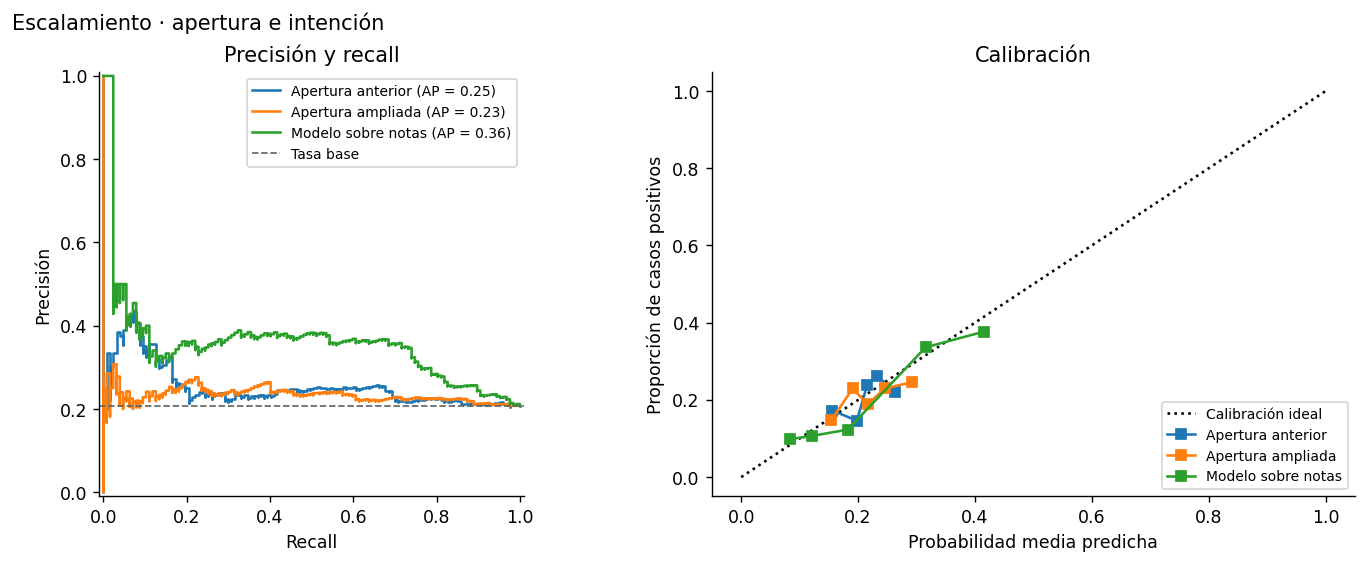

In [13]:
with threadpool_limits(limits=2):
    advanced_heldout = test_models(advanced_picks, advanced_features, advanced_models, y, dev, test)

def model_label(key):
    return " · ".join(key)

previous_opening = heldout[opening_key]
earlier_proxy = heldout[proxy_key]
customer_units = data["cliente_id"].iloc[test].to_numpy()
opening_report = prediction_report(actual, {
    "Apertura anterior": previous_opening,
    **{model_label(key): values for key, values in advanced_heldout.items() if key[0] == "Apertura ampliada"},
}, previous_opening, average_precision_score, units=customer_units)
proxy_report = prediction_report(actual, {
    "Intención inferida anterior": earlier_proxy,
    **{model_label(key): values for key, values in advanced_heldout.items() if key[0] != "Apertura ampliada"},
}, earlier_proxy, average_precision_score, units=customer_units)
display(opening_report.round(3))
display(proxy_report.round(3))
comparison_plots(actual, {
    "Apertura anterior": previous_opening,
    "Apertura ampliada": advanced_heldout[opening_selection],
    "Modelo sobre notas": advanced_heldout[proxy_selection],
}, "Escalamiento · apertura e intención")

### Mezcla de intención dura y probabilidades

La categoría inferida aporta un resumen estable y las probabilidades añaden matices. Combinamos los scores de riesgo de la logística previa y de la logística con probabilidades de intención. En las dos ventanas de desarrollo fijamos una mezcla por AP y otra por recall al 20 %, con los pesos predefinidos de la tabla. La cohorte de septiembre–octubre se compara con el mismo volumen de revisión.

In [14]:
soft_key = ("Apertura + probabilidades de intención", "Regresión logística L2")
hard_oof = champions.loc[proxy_key[0], "oof"]
soft_oof = advanced_picks.set_index(["Escenario", "Modelo"]).loc[soft_key, "oof"]
mix_trials = []
for weight in (0, 0.25, 0.5, 0.75, 1):
    oof_mix = (1 - weight) * hard_oof + weight * soft_oof
    mix_trials.append({
        "Peso de probabilidades": weight,
        "AP medio en desarrollo": np.mean([
            average_precision_score(y.iloc[val], oof_mix[val]) for _, val in dev_splits
        ]),
        "Recall medio al 20 % en desarrollo": np.mean([
            at_capacity(y.iloc[val], oof_mix[val], 0.20)["Recall"] for _, val in dev_splits
        ]),
    })
mix_trials = pd.DataFrame(mix_trials).set_index("Peso de probabilidades")
display(mix_trials.round(3))
criteria = {
    "Selección por AP": ["AP medio en desarrollo", "Recall medio al 20 % en desarrollo"],
    "Selección por recall al 20 %": ["Recall medio al 20 % en desarrollo", "AP medio en desarrollo"],
}
mix_weights = {name: mix_trials.sort_values(order, ascending=False, kind="stable").index[0]
               for name, order in criteria.items()}
mix_scores = {name: (1 - weight) * earlier_proxy + weight * advanced_heldout[soft_key]
              for name, weight in mix_weights.items()}
mix_report = prediction_report(actual, mix_scores, earlier_proxy, average_precision_score,
                               units=customer_units)
mix_report.insert(0, "Peso de probabilidades", pd.Series(mix_weights))
display(mix_report.round(3))

,AP medio en desarrollo,Recall medio al 20 % en desarrollo
Peso de probabilidades,,
0.00,0.321,0.306
0.25,0.320,0.300
0.50,0.319,0.309
0.75,0.318,0.317
1.00,0.320,0.316


,Peso de probabilidades,ROC-AUC,AP,Brier,Cambio de métrica principal,IC 95 % inferior,IC 95 % superior,Capturados al 20 %,Precisión al 20 %,Recall al 20 %,Lift al 20 %
Modelo o escenario,,,,,,,,,,,
Selección por AP,0.00,0.722,0.385,0.147,0.000,0.000,0.000,50,0.410,0.394,1.969
Selección por recall al 20 %,0.75,0.716,0.375,0.148,-0.009,-0.047,0.032,52,0.426,0.409,2.047


### Prueba con plantillas excluidas del entrenamiento

La prueba temporal original vuelve a encontrar las plantillas vistas en meses previos. Para el
modelo directo sobre notas seleccionado en desarrollo, volvemos a ajustar sus parámetros
congelados por cada plantilla del conjunto de prueba, omitiendo todas sus filas históricas.
Cada ticket conserva su fecha y aparece una sola vez. El resultado mide generalización dentro
del generador sintético con familias excluidas.

In [15]:
row = advanced_picks.set_index(["Escenario", "Modelo"]).loc[text_selection]
estimator, _ = advanced_models[text_selection[0]][text_selection[1]]
note_X = advanced_features[text_selection[0]]
heldout_templates = templates.iloc[test].to_numpy()
cold_scores = np.full(len(test), np.nan)
with threadpool_limits(limits=2):
    for template in pd.unique(heldout_templates):
        train_rows = dev[templates.iloc[dev].ne(template).to_numpy()]
        test_mask = heldout_templates == template
        assert templates.iloc[train_rows].ne(template).all()
        assert data["cierre_estimado"].iloc[train_rows].lt(pd.Timestamp("2026-09-01")).all()
        cold_scores[test_mask] = fits_and_scores(
            estimator, row["Parámetros"], note_X, y, train_rows, test[test_mask],
        )
assert np.isfinite(cold_scores).all()
regular_text = advanced_heldout[text_selection]
template_report = prediction_report(actual, {
    "Temporal": regular_text, "Temporal con plantilla excluida": cold_scores,
}, regular_text, average_precision_score, units=heldout_templates)
display(template_report.round(3))

def summary_line(label, values):
    scores = metrics(actual, values)
    captured = at_capacity(actual, values, 0.20)["Positivos capturados"]
    return f"**{label}** · AP **{decimal(scores['AP'])}**, **{captured}/{int(actual.sum())}** escalados al 20 %."

display(Markdown("\n\n".join([
    summary_line(model_label(opening_selection), advanced_heldout[opening_selection]),
    summary_line(model_label(proxy_selection), advanced_heldout[proxy_selection]),
    summary_line(f"{text_selection[0]} con plantilla excluida", cold_scores),
])))

,ROC-AUC,AP,Brier,Cambio de métrica principal,IC 95 % inferior,IC 95 % superior,Capturados al 20 %,Precisión al 20 %,Recall al 20 %,Lift al 20 %
Modelo o escenario,,,,,,,,,,
Temporal,0.676,0.321,0.159,0.000,0.000,0.000,44,0.361,0.346,1.732
Temporal con plantilla excluida,0.650,0.360,0.161,0.039,-0.046,0.132,44,0.361,0.346,1.732


**Apertura ampliada · XGBoost regularizado** · AP **0,235**, **30/127** escalados al 20 %.

**Apertura + probabilidades de intención · XGBoost regularizado** · AP **0,358**, **46/127** escalados al 20 %.

**Apertura + embeddings E5 con plantilla excluida** · AP **0,360**, **44/127** escalados al 20 %.

### Comprobación de transferencia al primer turno

El índice de transcripciones contiene el desenlace `escalado_nivel2`. Evaluamos ese desenlace
con los modelos de **solo texto** entrenados sobre notas de tickets. Usamos únicamente el primer
motivo expresado por el cliente y el entorno tabular de este control se limita al texto.
El volumen y la cantidad de positivos se informan junto al resultado. Esta verificación
exploratoria tiene un criterio de escalamiento registrado en el índice y no requiere enlazar
las transcripciones con los tickets.

In [16]:
import re

transcription_dir = insumos / "02_transcripciones"
index = pd.read_csv(transcription_dir / "indice_transcripciones.csv", encoding="utf-8-sig", dtype=str)
assert index["transcripcion_id"].is_unique and set(index["intencion"]) == LABELS

intake_question = re.compile(
    r"^(?:cuénteme\.|(?:cuénteme, |gracias\. )?¿en qué le "
    r"(?:ayudo|colaboro|puedo ayudar|puedo colaborar)(?: hoy)?\?)$"
)

def first_reason(transcript_id):
    path = transcription_dir / "llamadas" / f"{transcript_id}.txt"
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    reasons = [
        normalize(reply.removeprefix("CLIENTE:").strip())
        for advisor, reply in zip(lines, lines[1:])
        if advisor.startswith("ASESOR:")
        and intake_question.fullmatch(normalize(advisor.removeprefix("ASESOR:")))
        and reply.startswith("CLIENTE:")
    ]
    if len(reasons) != 1 or not reasons[0]:
        raise ValueError(f"No se pudo identificar un único motivo de atención en {transcript_id}.")
    return reasons[0]

transcripts = index.rename(columns={"intencion": "categoria"}).copy()
transcripts["texto"] = transcripts["transcripcion_id"].map(first_reason)
transcripts["plantilla"] = transcripts["texto"].map(group)

In [17]:
first_turn_targets = transcripts["resultado"].eq("escalado_nivel2").astype(int)
assert first_turn_targets.nunique() == 2
first_turn_sets = {
    "Solo notas TF-IDF": transcripts["texto"].to_frame("nota"),
    "Solo embeddings E5": encode_texts(transcripts["texto"]).add_prefix("e5_"),
}
first_turn_results = {}
with threadpool_limits(limits=2):
    for name, X in first_turn_sets.items():
        key = (name, "Regresión logística L2")
        estimator, _ = advanced_models[key[0]][key[1]]
        params = advanced_picks.set_index(["Escenario", "Modelo"]).loc[key, "Parámetros"]
        trained = clone(estimator).set_params(**params).fit(advanced_features[name].iloc[dev], y.iloc[dev])
        assert list(trained.feature_names_in_) == list(X)
        first_turn_results[name] = trained.predict_proba(X)[:, 1]

majority = float(first_turn_targets.mean())
first_turn_overview = pd.DataFrame.from_dict({
    key: {**metrics(first_turn_targets, values), **at_capacity(first_turn_targets, values, 0.20)}
    for key, values in first_turn_results.items()
}, orient="index")
print(f"{len(transcripts)} transcripciones · {int(first_turn_targets.sum())} escalados a nivel 2 · "
      f"{transcripts['plantilla'].nunique()} familias de frases · AP del baseline {decimal(majority)}")
display(first_turn_overview.round(3))

50 transcripciones · 3 escalados a nivel 2 · 15 familias de frases · AP del baseline 0,060


,ROC-AUC,AP,Brier,Revisados,Positivos capturados,Falsos positivos,Precisión,Recall,Lift
Solo notas TF-IDF,0.908,0.729,0.057,10,2,8,0.2,0.667,3.333
Solo embeddings E5,0.929,0.410,0.224,10,3,7,0.3,1.000,5.000


Los cambios de AP se acompañan de intervalos pareados por cliente en la prueba temporal y por
plantilla en el control sin plantillas vistas. El resultado de apertura es el que corresponde
a los campos disponibles al crear el ticket. La transferencia del texto necesita más primeros
turnos con desenlaces verificados por canal. Para evaluar una intervención se requeriría observar
también si la alerta permitió actuar y qué escalados debían ocurrir.